# 04 - Visualizations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sqlalchemy import create_engine

engine = create_engine("sqlite:///data/movies.db")
movies = pd.read_sql("SELECT * FROM movies", engine, parse_dates=["release_date"])
genres = pd.read_sql("SELECT * FROM genres", engine)
movie_genres = pd.read_sql("SELECT * FROM movie_genres", engine)


movies_clean = movies.copy()
movies_clean[["budget", "revenue"]] = movies_clean[["budget", "revenue"]].replace(0, np.nan)

sns.set_theme(style="whitegrid")
print(movies.shape)

(2503, 12)


## 1: Distribution of movie budgets

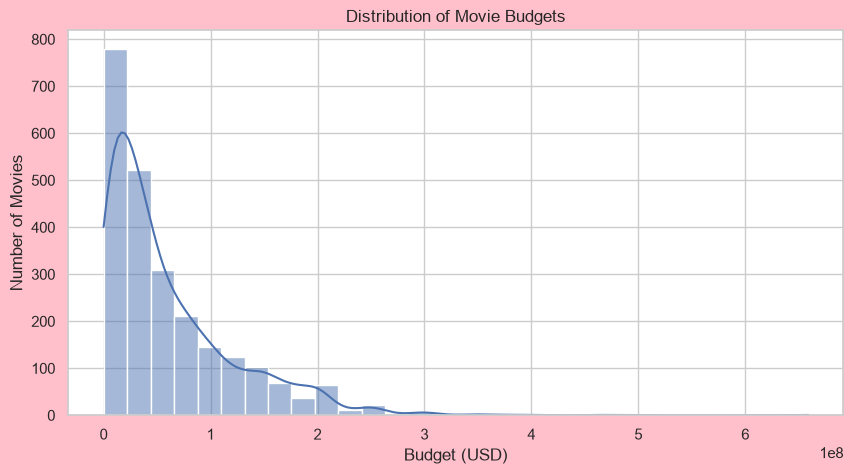

In [2]:
plt.figure(figsize=(10, 5),facecolor="pink")
sns.histplot(data=movies_clean.dropna(subset="budget"),x="budget", bins=30, kde=True)
plt.title("Distribution of Movie Budgets")
plt.xlabel("Budget (USD)")
plt.ylabel("Number of Movies")
plt.show()



### Insight

1. Most movies have relatively low budgets, as the highest number of movies are concentrated in the lower budget range.
2. As the budget increases, the number of movies decreases significantly.
3. Only a small number of movies have very high budgets.
4. This indicates that low- and medium-budget movies are much more common than high-budget productions.



## 2: Runtime distribution (box plot)

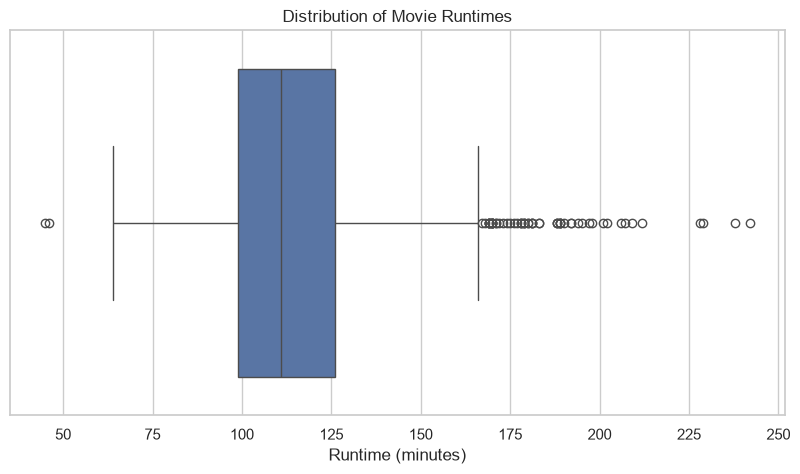

In [3]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=movies,x="runtime")
plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (minutes)")
plt.show() 

### Insight
1. Most movie runtimes are concentrated between 98 and 125 minutes, indicating that this is the typical duration for the majority of movies.
2. The median runtime is around 110 minutes, which shows that an average movie usually runs for about 1 hour and 50 minutes.
3. The box plot shows a few outliers on both sides, with very short movies below the lower bound and several very long movies above the upper bound.
4. A larger number of outliers are present on the higher side, suggesting that while most movies follow a standard runtime, some movies have significantly longer durations than the majority.

## 3: Distribution of vote_average (histogram)

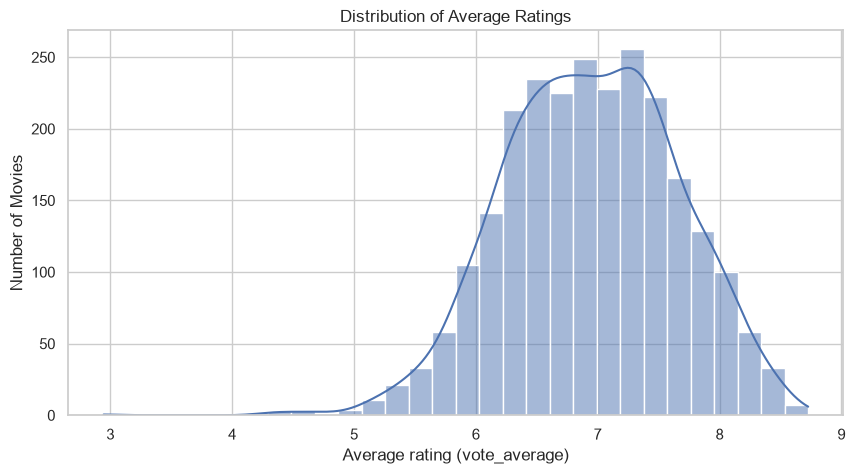

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(data=movies,x="vote_average", bins=30, kde=True)
plt.title("Distribution of Average Ratings")
plt.xlabel("Average rating (vote_average)")
plt.ylabel("Number of Movies") 
plt.show() 

### Insight
1. Most movies have an average rating between 6 and 8, indicating that the majority of movies receive moderate to good audience ratings.
2. The highest concentration of movies is around the 6.5 to 7.5 rating range, which appears to be the most common rating range in the dataset.
3. Very few movies have extremely low ratings below 5, and only a small number of movies achieve very high ratings above 8.5.
4. The distribution is centered around 7, suggesting that most movies are rated fairly well and extreme ratings are less common.

## 4. Count of movies per genre (bar plot)

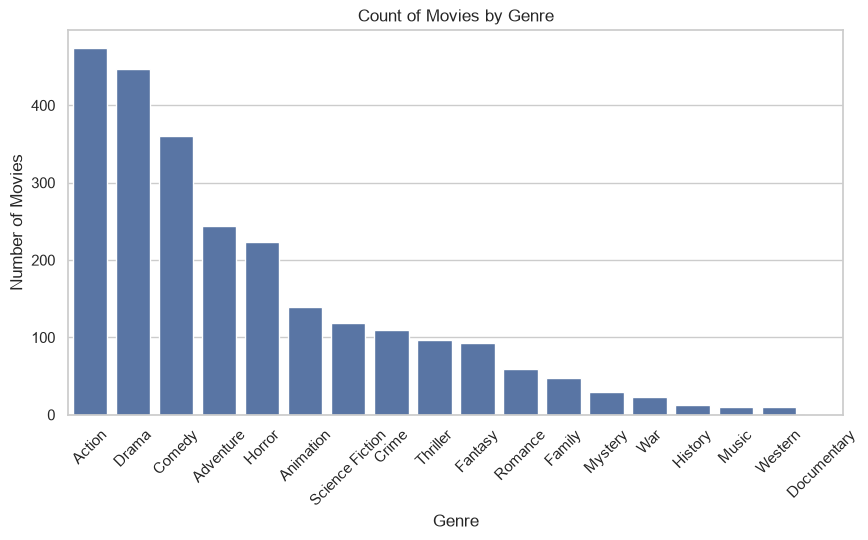

In [5]:
primary = movie_genres.drop_duplicates(subset="movie_id", keep="first")
primary = pd.merge(primary,genres, on="genre_id", how="left")
movies_pg = pd.merge(movies_clean,primary[["movie_id", "genre_name"]], on="movie_id", how="left")
movies_pg = movies_pg.rename(columns={"genre_name": "primary_genre"})

movies_count_per_genre = movies_pg.groupby("primary_genre")["movie_id"].count().sort_values(ascending=False).reset_index()
movies_count_per_genre = movies_count_per_genre.rename(columns={"movie_id":"movie_count"})
plt.figure(figsize=(10, 5))
sns.barplot(data=movies_count_per_genre,x="primary_genre",y="movie_count")
plt.title("Count of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

### Insight
1. The Action genre has the highest number of movies in the dataset, followed by Drama and Comedy. This shows that these genres are the most commonly produced movie categories.
2. Genres such as Adventure, Horror, and Animation also have a noticeable number of movies, but their counts are considerably lower than the top three genres.
3. Genres like History, Music, Western, and Documentary have very few movies compared to other genres, indicating lower representation in the dataset.
4. Overall, the chart shows that movie production is concentrated in a few popular genres, with Action, Drama, and Comedy accounting for a large share of the movies.

## 5. Budget vs revenue (scatter with trend line), known values only

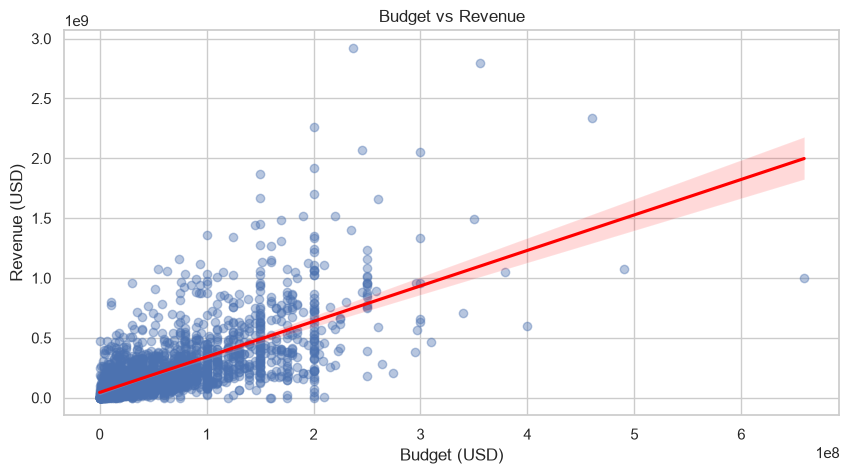

In [6]:
known_budget_and_revenue_movies = movies_clean.dropna(subset=["budget", "revenue"])
plt.figure(figsize=(10, 5))
sns.regplot(data=known_budget_and_revenue_movies, x="budget", y="revenue", scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Budget vs Revenue")
plt.xlabel("Budget (USD)")
plt.ylabel("Revenue (USD)") 
plt.show() 


### Insight
1. The chart shows a positive relationship between budget and revenue, as the trend line moves upward from left to right. This indicates that movies with higher budgets generally tend to generate higher revenues.
2. Most movies are concentrated in the lower budget range, and these movies also tend to earn lower revenues compared to high-budget movies.
3. There are a few movies with very high budgets and revenues, but some high-budget movies have generated relatively low revenues, indicating that a larger budget does not always guarantee success.
4. The wide spread of points around the trend line suggests that factors other than budget, such as genre, cast and marketing may also influence a movie's revenue.

## 6. Popularity vs vote count (scatter plot)

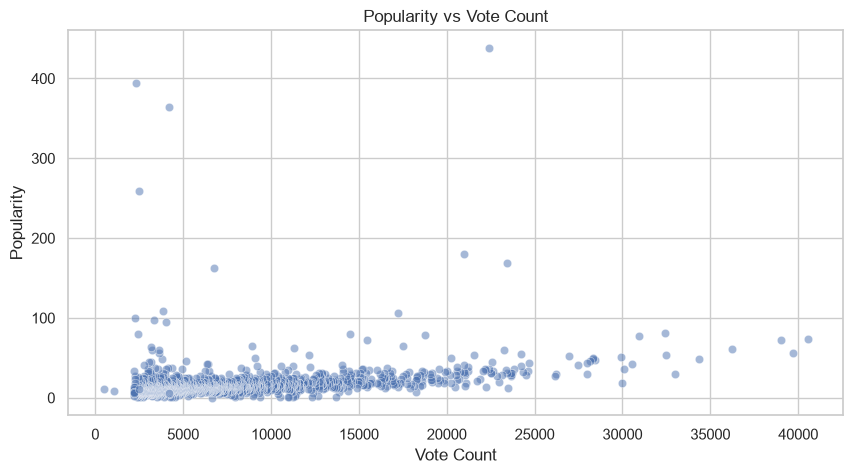

In [7]:
plt.figure(figsize=(10, 5)) 
sns.scatterplot(data=movies, x="vote_count", y="popularity", alpha=0.5) 
plt.title("Popularity vs Vote Count") 
plt.xlabel("Vote Count") 
plt.ylabel("Popularity") 
plt.show()

### Insight
1. Most movies have a popularity score below 50, even though their vote counts vary widely across the dataset.
2. The majority of movies are concentrated in the lower popularity range, while only a few movies achieve very high popularity scores above 100.
3. A small number of movies stand out as outliers with exceptionally high popularity and vote counts compared to the rest of the dataset.
4. The chart suggests a weak positive relationship between vote count and popularity, as movies with higher vote counts generally tend to have higher popularity, although there are several exceptions.

## 7.  Number of movies released per year  (bar chart)

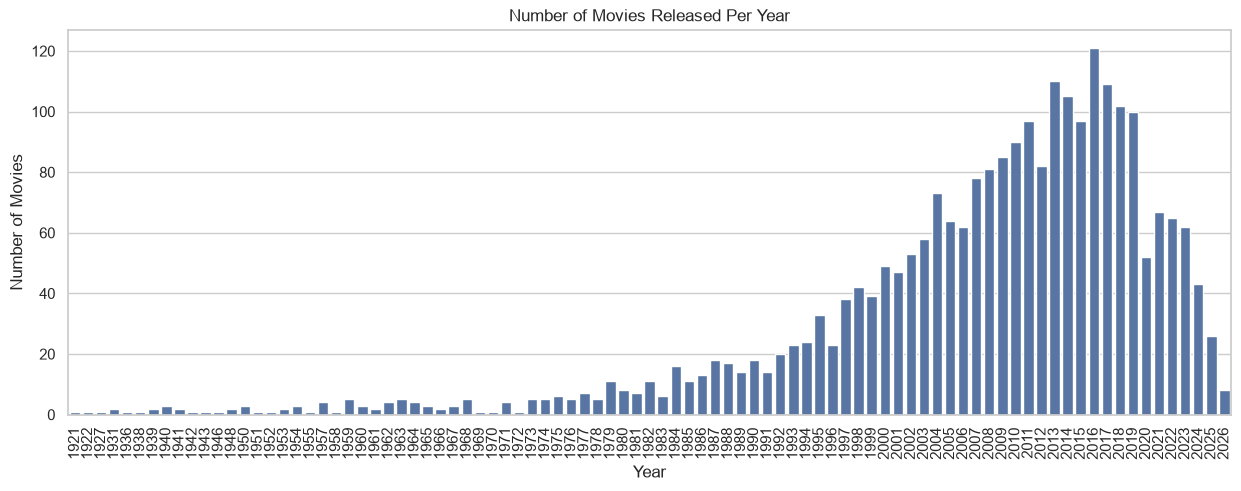

In [8]:
movies["release_year"] = pd.to_datetime(movies["release_date"]).dt.year
movies_per_year = movies["release_year"].value_counts().sort_index()
plt.figure(figsize=(15,5))
sns.barplot(x=movies_per_year.index,y=movies_per_year.values)
plt.title("Number of Movies Released Per Year")
plt.xlabel("Year")
plt.xticks(rotation=90)
plt.ylabel("Number of Movies")
plt.show()

### Insight
1. The number of movies released per year has generally increased over time, especially from the mid-1990s onwards.
2. Movie production grew significantly between 2000 and 2018, indicating a steady increase in film releases during this period.
3. The highest number of movies in the dataset were released around 2016, making it the peak year for movie releases.
4. The earlier years contain very few movies compared to recent years, while the lower counts after 2020 may be due to limited records available in the dataset rather than an actual decline in movie production.

## 8. Average rating by genre (bar chart)

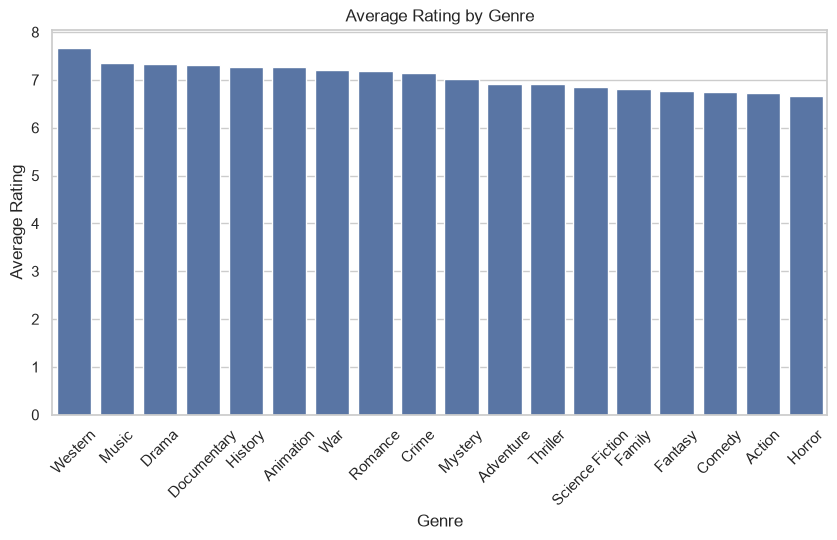

In [9]:
primary = movie_genres.drop_duplicates(subset="movie_id", keep="first")
primary = pd.merge(primary,genres, on="genre_id", how="left")
movies_pg = pd.merge(movies_clean,primary[["movie_id", "genre_name"]], on="movie_id", how="left")
movies_pg = movies_pg.rename(columns={"genre_name": "primary_genre"})

genre_avrg_rating = movies_pg.groupby("primary_genre")["vote_average"].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=genre_avrg_rating, x="primary_genre", y="vote_average")
plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.show()

### Insight
1. The average ratings of all genres fall within a narrow range of approximately 6.6 to 7.7, indicating that audience ratings are fairly consistent across genres.
2. Western movies have the highest average rating, followed by Music and Drama, suggesting that movies in these genres tend to receive better audience ratings.
3. Genres such as Action, Comedy, and Horror have comparatively lower average ratings, although their ratings are still above 6.5.
4. The difference between the highest-rated and lowest-rated genres is not very large, which shows that no genre is rated dramatically better or worse than the others in this dataset.

## 9: Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count

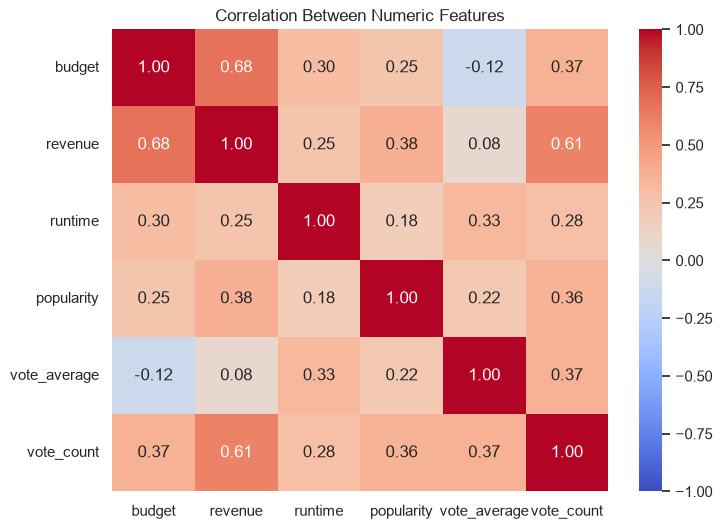

In [10]:
corr = movies_clean[["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Numeric Features")
plt.show()

### Insight
1. The strongest positive correlation is between budget and revenue (0.68), indicating that movies with higher budgets generally tend to generate higher revenue.
2. Revenue and vote count (0.61) also show a strong positive relationship, suggesting that movies earning higher revenues often receive more audience votes.
3. Most other correlations are weak to moderate, indicating that no single factor completely determines a movie's success.
4. Budget and vote_average (-0.12) have a very weak negative correlation, showing that spending more money on a movie does not necessarily result in higher audience rating.

## 10: Budget vs revenue, colored by primary genre, size = vote_count

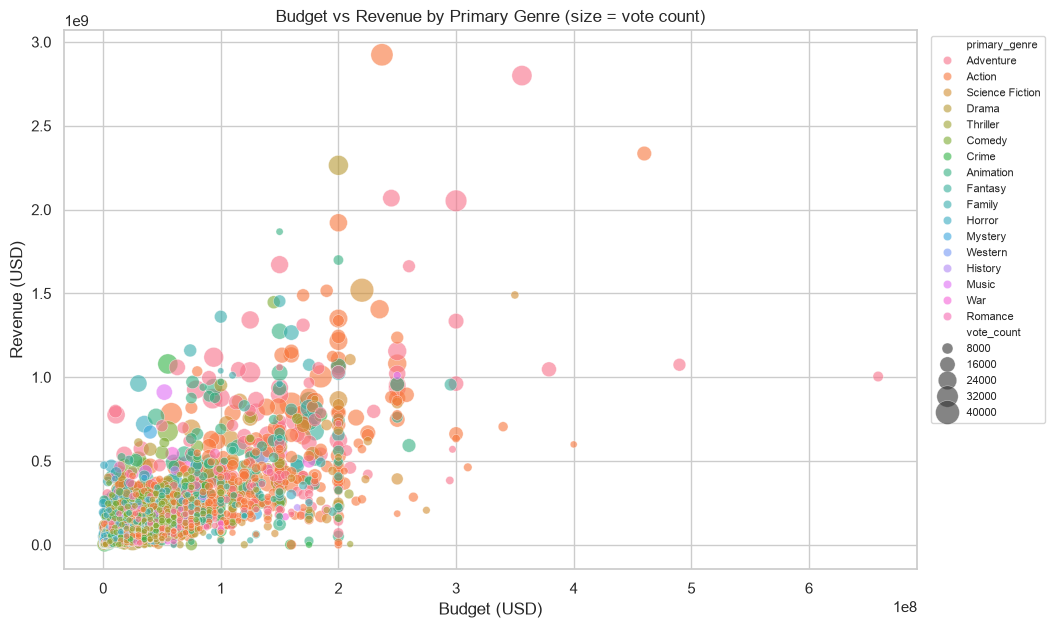

In [11]:
primary = movie_genres.drop_duplicates(subset="movie_id", keep="first")
primary = pd.merge(primary,genres, on="genre_id", how="left")
movies_pg = pd.merge(movies_clean,primary[["movie_id", "genre_name"]], on="movie_id", how="left")
movies_pg = movies_pg.rename(columns={"genre_name": "primary_genre"})

known_pg = movies_pg.dropna(subset=["budget", "revenue", "primary_genre"])

plt.figure(figsize=(11, 7))
sns.scatterplot(data=known_pg, x="budget", y="revenue", hue="primary_genre", size="vote_count", sizes=(20,300), alpha=0.6)
plt.title("Budget vs Revenue by Primary Genre (size = vote count)")
plt.xlabel("Budget (USD)")
plt.ylabel("Revenue (USD)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()

### Insight
1. The chart shows that movies from different genres are distributed across various budget and revenue ranges, with each color representing a different genre and the bubble size representing the vote count received by the movie.
2. Most movies are concentrated in the lower budget and lower revenue range, indicating that a large number of movies are produced with moderate budgets and generate moderate revenues.
3. While higher-budget movies generally tend to earn higher revenues, there are several exceptions where movies with large budgets generated comparatively lower revenues, showing that a high budget does not always guarantee commercial success.
4. Larger bubbles are mostly seen among movies with higher revenues, suggesting that movies which attract more audience attention and votes often tend to perform better at the box office.